# BatChat vs the crowd: where Batman fans disagree

*Red Rain* is **#6** on BatChat's list. On Goodreads, it gets **3.66/5**. *White Knight* gets **4.28/5**, but BatChat puts it at **#734**. [Goodreads: Red Rain](https://www.goodreads.com/book/show/72479.Batman_Dracula) · [White Knight](https://www.goodreads.com/book/show/37775321-batman)

Which other books divide the podcast and its fellow readers? And do the hosts agree more with readers or critics?

We'll compare [740 stories ranked by Matt Lazorwitz and Will Nevin on BatChat](https://comicsxf.com/batchat-rankings/) with Goodreads and Comic Book RoundUp. **Rank 1 is best. Higher outside ratings are better.** The data is a snapshot from **21 October 2026**.

*By [Dan Ofer](https://scholar.google.com/citations?user=uDx2ItYAAAAJ), as part of [BatRank](https://github.com/ddofer/BatRank). [Start with the Batman EDA](2.0-batchat-the-art-of-gotham.ipynb) for writers, eras, heroes, and villains.*

In [1]:
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from pathlib import Path

candidates = [Path.cwd(), Path.cwd().parent]
candidates += [p.parents[2] for p in Path("/kaggle/input").glob("**/data/processed/stories.csv")]
DATA_ROOT = next(p for p in candidates if (p / "data/processed/stories.csv").exists())
sys.path.insert(0, str(DATA_ROOT))
from scripts.analysis import load_data, grouped_folds, save_figure, COLORS  # noqa: E402 — locate the downloaded dataset first

ROOT, REPORT, s, issues = load_data()
N = len(s)
s["preference"] = 1 - s.rank_percentile
print(
    f"{N:,} ranked entries · {len(issues):,} issue references · snapshot {s.snapshot_date.iloc[0]}"
)

740 ranked entries · 2,434 issue references · snapshot 2026-10-21


## 1. First, compare the same comic

*Ego and Other Tails* contains more than *Ego*. *Court of Owls* Volume 1 stops before BatChat's selection does. Those ratings answer a different question, so we leave them out.

Goodreads must cover the same story. RoundUp must cover every issue, without unrelated stories sharing the issue's score. An *Elegy* issue's rating, for example, might also reflect its backup.

That leaves a small fraction of the list:

In [2]:
from scripts.analysis import correlation_interval

from scipy.stats import spearmanr

sources = {
    "Goodreads readers": {
        "score": "goodreads_rating",
        "count": "goodreads_rating_count",
        "minimum": 100,
    },
    "RoundUp readers": {
        "score": "roundup_user_rating",
        "count": "roundup_user_min_count",
        "minimum": 5,
    },
    "RoundUp critics": {
        "score": "roundup_critic_rating",
        "count": "roundup_critic_min_count",
        "minimum": 3,
    },
}


def eligibility(label, minimum=None):
    spec = sources[label]
    minimum = spec["minimum"] if minimum is None else minimum
    if label == "Goodreads readers":
        match = s.goodreads_match_scope.eq("same_story")
    else:
        audience = "user" if label == "RoundUp readers" else "critic"
        match = s[f"roundup_{audience}_complete"] & s.roundup_narrative_scope.eq(
            "all_indexed_narratives"
        )
    return match & s[spec["count"]].ge(minimum)


coverage = []
for label, spec in sources.items():
    ok = eligibility(label)
    coverage.append(
        {
            "audience": label,
            "any_score": s[spec["score"]].notna().sum(),
            "matched_and_count_screened": ok.sum(),
            "median_BatChat_rank": s.loc[ok, "rank"].median(),
        }
    )
coverage = pd.DataFrame(coverage)
display(
    coverage.rename(
        columns={
            "audience": "Audience",
            "any_score": "Any score found",
            "matched_and_count_screened": "Comparable stories",
            "median_BatChat_rank": "Median BatChat rank · lower = better",
        }
    ).set_index("Audience")
)
coverage.to_csv(REPORT / "external_rating_coverage.csv", index=False)


groups, folds = grouped_folds(s, issues)
cohorts = {label: s[eligibility(label)].copy() for label in sources}

,Any score found,Comparable stories,Median BatChat rank · lower = better
Audience,,,
Goodreads readers,55,40,113.5
RoundUp readers,326,110,245.0
RoundUp critics,174,78,282.5


The Goodreads books lean toward BatChat's favorites: their median rank is **113.5**. RoundUp covers a less favored selection. We'll need to remember this when comparing audiences.

<details><summary>Matching and minimum review counts</summary>

We require 100 Goodreads ratings, or at least five RoundUp reader ratings or three critic reviews per issue. Arc scores are equal-weight averages of their issue scores. The same person may review several issues.

A matched story can still have different coloring or extras across editions. Ratings may also postdate the podcast episode. These comparisons describe the saved scores, not what readers thought when BatChat first discussed the book.

</details>

## 2. Which books divide BatChat and Goodreads?

Put **the same 40 books** in order twice: once by BatChat rank, once by Goodreads rating. The chart shows the five biggest disagreements in each direction.

**Farther right means more favored.** Blue is BatChat; orange is Goodreads. A long line means the audiences put that book in very different places.

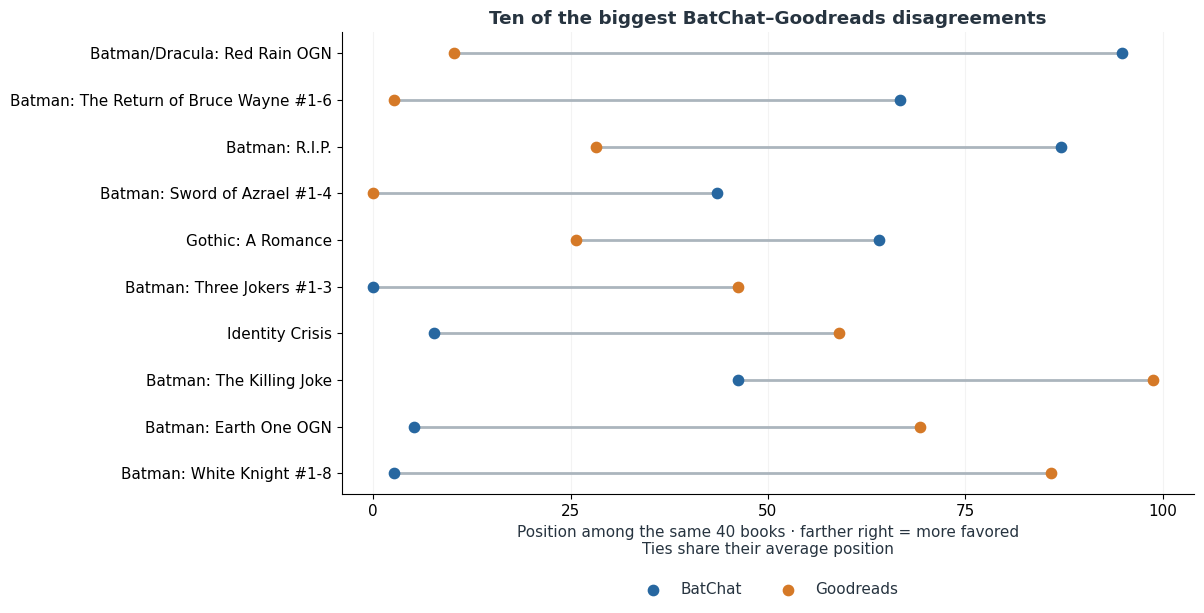

In [3]:
hot = []
for label, frame in cohorts.items():
    frame = frame.copy()
    column = sources[label]["score"]
    frame["batchat_cohort_percentile"] = (frame.preference.rank(method="average") - 1) / (
        len(frame) - 1
    )
    frame["external_cohort_percentile"] = (frame[column].rank(method="average") - 1) / (
        len(frame) - 1
    )
    frame["preference_gap"] = frame.batchat_cohort_percentile - frame.external_cohort_percentile
    frame["audience"] = label
    frame["external_score"] = frame[column]
    hot.append(frame)
hot = pd.concat(hot, ignore_index=True)
cols = [
    "audience",
    "story_id",
    "title",
    "rank",
    "external_score",
    "preference_gap",
    "goodreads_url",
]
hot[cols].to_csv(REPORT / "external_hot_takes.csv", index=False)
shown = hot[hot.audience.eq("Goodreads readers")]
shown = pd.concat(
    [shown.nlargest(5, "preference_gap"), shown.nsmallest(5, "preference_gap")]
).sort_values("preference_gap")
fig, ax = plt.subplots(figsize=(11, 6))
ax.hlines(
    shown.title,
    100 * shown.batchat_cohort_percentile,
    100 * shown.external_cohort_percentile,
    color="#ABB5BD",
    lw=2,
)
ax.scatter(
    100 * shown.batchat_cohort_percentile,
    shown.title,
    color=COLORS["blue"],
    label="BatChat",
    s=55,
    zorder=3,
)
ax.scatter(
    100 * shown.external_cohort_percentile,
    shown.title,
    color=COLORS["orange"],
    label="Goodreads",
    s=55,
    zorder=3,
)
ax.set(
    xlabel="Position among the same 40 books · farther right = more favored\nTies share their average position",
    title="Ten of the biggest BatChat–Goodreads disagreements",
    xlim=(-4, 104),
    xticks=[0, 25, 50, 75, 100],
)
ax.xaxis.grid(True, alpha=0.15)
ax.set_axisbelow(True)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, frameon=False)
save_figure(fig, REPORT, "crowd-hot-takes")

*Red Rain* sits near the top for BatChat and near the bottom for Goodreads. *White Knight* goes the other way. Their gaps are **84.6** and **83.3 points** on this 0–100 scale.

Both books change Batman's world. Doug Moench and Kelley Jones turn him into a vampire. Sean Murphy makes a supposedly rehabilitated Joker his political challenger. “The hosts dislike unconventional Batman” doesn't explain these results. These ratings tell us where the audiences disagree, but not why. [DC: Red Rain](https://www.dc.com/graphic-novels/batman-and-dracula-trilogy-1991/tales-of-the-multiverse-batman-vampire) · [White Knight](https://www.dc.com/blog/2017/07/07/sean-murphy-s-batman-white-knight-arrives-october-4)

Two disagreements recur across all three sources. BatChat puts *The Return of Bruce Wayne* at **#53**, relatively higher than every comparison audience does. It puts *White Knight* relatively lower than all three.

<details><summary>What the 0–100 scale means</summary>

The 0–100 scale describes position in each audience’s ordered list. Tied scores share their average position, so a tie at the top can fall just below 100. A gap measures relative standing among these books, not stars or places on the full list.

Audience disagreement doesn't tell us whether readers within either audience are divided. We'd need individual ratings to distinguish a love-it-or-hate-it book from one most readers find middling.

</details>

## 3. Is there much agreement overall?

Some. Better-rated books tend to rank better with BatChat, but the scatter is considerable. **Each dot is one story.** Better outside ratings run right; better BatChat ranks run up.

Spearman correlation summarizes agreement in ordering: **1 means the same order; 0 means no consistent relationship.** We reverse BatChat's ranks for this calculation so that positive numbers mean agreement.

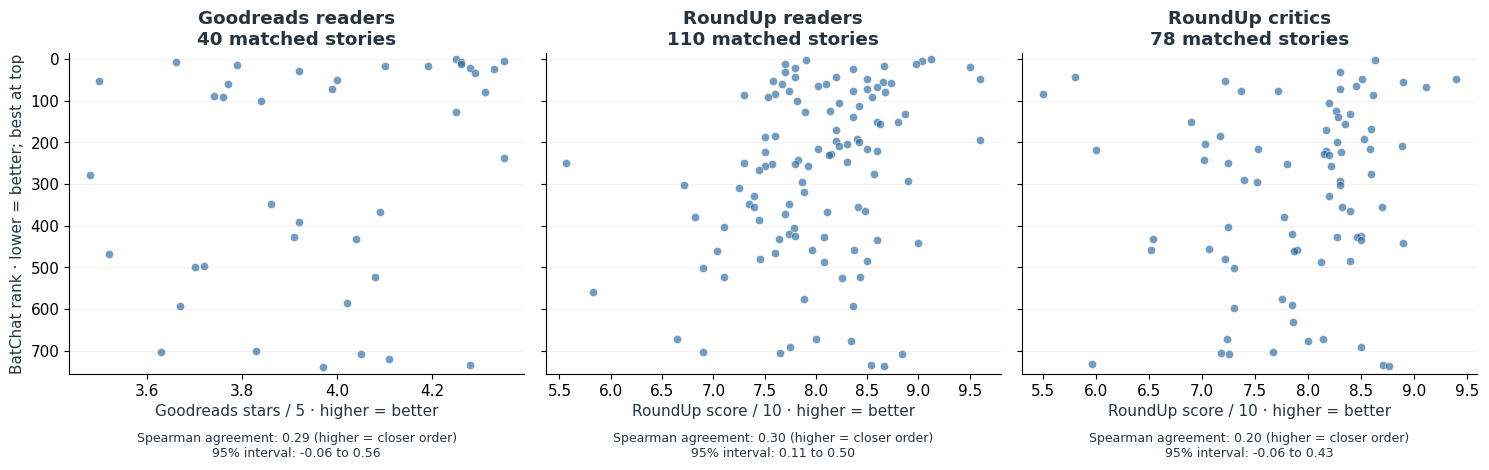

In [4]:
correlations = []
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, (label, frame) in zip(axes, cohorts.items()):
    column = sources[label]["score"]
    rho = spearmanr(frame.preference, frame[column]).statistic
    block = pd.Series(groups, index=s.index).loc[frame.index]
    low, high = correlation_interval(frame.preference, frame[column], block)
    correlations.append(
        {"audience": label, "n": len(frame), "spearman": rho, "ci_low": low, "ci_high": high}
    )
    ax.scatter(
        frame[column],
        frame["rank"],
        s=35,
        alpha=0.65,
        color=COLORS["blue"],
        edgecolors="white",
        linewidth=0.5,
    )
    ax.set(
        title=f"{label}\n{len(frame)} matched stories",
        xlabel="Goodreads stars / 5 · higher = better"
        if label == "Goodreads readers"
        else "RoundUp score / 10 · higher = better",
    )
    ax.set_ylim(N + 15, -15)
    ax.yaxis.grid(True, alpha=0.15)
    ax.set_axisbelow(True)
    ax.text(
        0.5,
        -0.26,
        f"Spearman agreement: {rho:.2f} (higher = closer order)\n95% interval: {low:.2f} to {high:.2f}",
        transform=ax.transAxes,
        fontsize=9,
        ha="center",
    )
axes[0].set_ylabel("BatChat rank · lower = better; best at top")
fig.tight_layout()
save_figure(fig, REPORT, "crowd-agreement")
correlations = pd.DataFrame(correlations)
correlations.to_csv(REPORT / "external_rating_correlations.csv", index=False)

RoundUp readers have the highest correlation with BatChat: **0.30**, compared with **0.29** for Goodreads and **0.20** for critics. The uncertainty intervals are wide. Goodreads and critics both include zero.

It's tempting to say the hosts agree more with readers than critics. But the panels contain different books. Let's give everyone the same list.

## 4. Readers or critics? Hold the books fixed

**69 stories** have enough reader and critic ratings for a direct RoundUp comparison. Here are the largest score gaps. Both audiences use a ten-point scale; a **positive difference means critics scored the story higher**.

In [5]:
sensitivity = []
thresholds = {
    "Goodreads readers": [100, 1000, 5000, 10000],
    "RoundUp readers": [1, 3, 5, 10, 20],
    "RoundUp critics": [1, 3, 5, 10],
}
for label, limits in thresholds.items():
    for minimum in limits:
        frame = s[eligibility(label, minimum)]
        if len(frame) >= 8:
            sensitivity.append(
                {
                    "audience": label,
                    "minimum_count": minimum,
                    "n": len(frame),
                    "spearman": spearmanr(
                        frame.preference, frame[sources[label]["score"]]
                    ).statistic,
                }
            )
sensitivity = pd.DataFrame(sensitivity)
sensitivity.to_csv(REPORT / "external_vote_sensitivity.csv", index=False)

paired = s[eligibility("RoundUp readers") & eligibility("RoundUp critics")].copy()
paired["critic_minus_reader"] = paired.roundup_critic_rating - paired.roundup_user_rating

display(
    pd.concat(
        [paired.nlargest(5, "critic_minus_reader"), paired.nsmallest(5, "critic_minus_reader")]
    )[["title", "rank", "roundup_critic_rating", "roundup_user_rating", "critic_minus_reader"]]
    .rename(
        columns={
            "title": "Story",
            "rank": "BatChat rank · 1 = best",
            "roundup_critic_rating": "Critics / 10 · higher = better",
            "roundup_user_rating": "Readers / 10 · higher = better",
            "critic_minus_reader": "Critics − readers · positive = critics higher",
        }
    )
    .set_index("Story")
    .round(2)
)
paired[
    [
        "story_id",
        "title",
        "rank",
        "roundup_critic_rating",
        "roundup_user_rating",
        "critic_minus_reader",
    ]
].to_csv(REPORT / "critic_reader_disagreements.csv", index=False)

,BatChat rank · 1 = best,Critics / 10 · higher = better,Readers / 10 · higher = better,Critics − readers · positive = critics higher
Story,,,,
Being Robin,250,7.25,5.57,1.68
Shadows,302,8.30,6.72,1.58
Batman: Black and White V.4,87,8.62,7.30,1.32
Sharkbite,356,8.70,7.40,1.30
Mindfields,380,7.78,6.82,0.95
Slay Ride,42,5.80,8.20,-2.40
The Clown at Midnight,85,5.50,7.60,-2.10
Batman and Son,458,6.52,8.38,-1.85
Blackest Knight,152,6.90,8.60,-1.70


Readers give *Slay Ride* **8.2**, versus critics' **5.8**. BatChat ranks it **#42**. Readers also favor *The Clown at Midnight*, Grant Morrison and John Van Fleet's illustrated prose story: **7.6 versus 5.5**. BatChat puts it at **#85**.

Those are selected examples. Across all 69 stories, **BatChat correlates 0.18 with readers and 0.16 with critics**. The supposed reader advantage has almost disappeared. Readers and critics agree more with each other, at **0.44**.

## 5. The more interesting difference is publication year

Agreement in ordering and generosity in scoring are different things. Two audiences could put every book in the same order while one gives everything an extra point.

The right panel below shows **critic score minus reader score**, grouped by publication decade. Above zero, critics scored the book higher. Below zero, readers did. Dots are stories; bars mark medians.

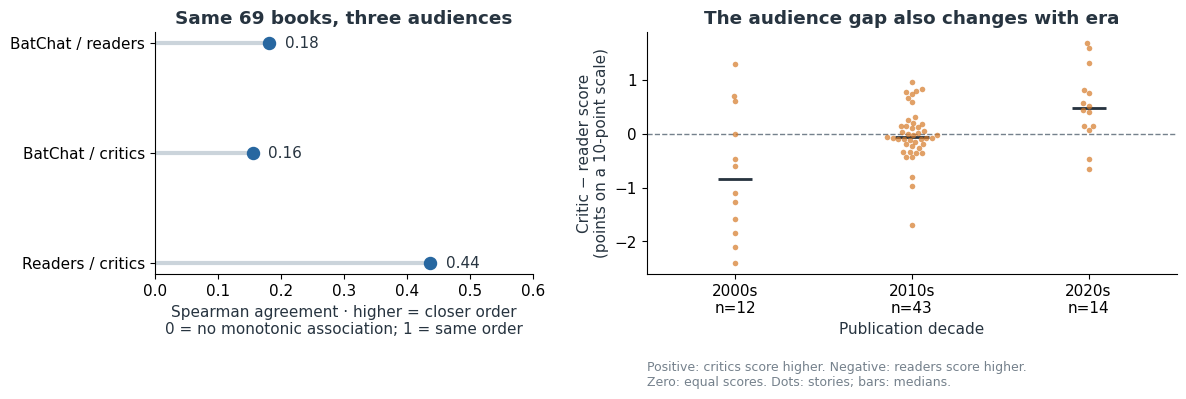

732

In [6]:
# Hold the books fixed for all three comparisons.
paired["decade"] = (paired.cover_year_start // 10 * 10).astype(int)
pair_correlations = pd.DataFrame(
    [
        {
            "comparison": "BatChat / readers",
            "rho": spearmanr(-paired["rank"], paired.roundup_user_rating).statistic,
        },
        {
            "comparison": "BatChat / critics",
            "rho": spearmanr(-paired["rank"], paired.roundup_critic_rating).statistic,
        },
        {
            "comparison": "Readers / critics",
            "rho": spearmanr(paired.roundup_user_rating, paired.roundup_critic_rating).statistic,
        },
    ]
)
values = paired[
    [
        "rank",
        "roundup_user_rating",
        "roundup_critic_rating",
        "cover_year_start",
        "critic_minus_reader",
    ]
].to_numpy()
labels = pd.Series(groups, index=s.index).loc[paired.index].to_numpy()
blocks = [np.flatnonzero(labels == g) for g in np.unique(labels)]
rng = np.random.default_rng(42)
bootstrap = []
for _ in range(2000):
    draw = values[np.concatenate([blocks[k] for k in rng.integers(0, len(blocks), len(blocks))])]
    reader_rho = spearmanr(-draw[:, 0], draw[:, 1]).statistic
    critic_rho = spearmanr(-draw[:, 0], draw[:, 2]).statistic
    bootstrap.append([reader_rho - critic_rho, spearmanr(draw[:, 3], draw[:, 4]).statistic])
intervals = np.nanquantile(bootstrap, [0.025, 0.975], axis=0)
comparison = {
    "n_readings": len(paired),
    "n_connected_groups": len(blocks),
    "reader_minus_critic_rho": pair_correlations.rho.iloc[0] - pair_correlations.rho.iloc[1],
    "difference_ci_low": intervals[0, 0],
    "difference_ci_high": intervals[1, 0],
    "year_gap_rho": spearmanr(paired.cover_year_start, paired.critic_minus_reader).statistic,
    "year_gap_ci_low": intervals[0, 1],
    "year_gap_ci_high": intervals[1, 1],
}

era_gaps = paired.groupby("decade").critic_minus_reader.agg(n="size", median="median")
era_gaps.to_csv(REPORT / "critic_reader_gap_by_era.csv")


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].hlines(range(3), 0, pair_correlations.rho, color="#CBD4DB", lw=3)
axes[0].scatter(pair_correlations.rho, range(3), s=75, color=COLORS["blue"], zorder=3)
for row in pair_correlations.itertuples():
    axes[0].text(row.rho + 0.025, row.Index, f"{row.rho:.2f}", va="center")
axes[0].set(
    yticks=range(3),
    yticklabels=pair_correlations.comparison,
    xlim=(0, 0.6),
    xlabel="Spearman agreement · higher = closer order\n0 = no monotonic association; 1 = same order",
    title=f"Same {len(paired)} books, three audiences",
)
axes[0].invert_yaxis()
sns.swarmplot(
    data=paired,
    x="decade",
    y="critic_minus_reader",
    order=era_gaps.index,
    color=COLORS["orange"],
    size=4,
    alpha=0.7,
    ax=axes[1],
)
sns.pointplot(
    data=paired,
    x="decade",
    y="critic_minus_reader",
    order=era_gaps.index,
    estimator="median",
    errorbar=None,
    linestyle="none",
    markers="_",
    markersize=24,
    color="#273440",
    ax=axes[1],
)
axes[1].axhline(0, color=COLORS["grey"], lw=1, ls="--")
axes[1].set(
    xticks=range(len(era_gaps)),
    xticklabels=[f"{d}s\nn={int(r.n)}" for d, r in era_gaps.iterrows()],
    ylabel="Critic − reader score\n(points on a 10-point scale)",
    xlabel="Publication decade",
    title="The audience gap also changes with era",
)
axes[1].text(
    0,
    -0.36,
    "Positive: critics score higher. Negative: readers score higher.\nZero: equal scores. Dots: stories; bars: medians.",
    transform=axes[1].transAxes,
    fontsize=9,
    color=COLORS["grey"],
    va="top",
)
fig.tight_layout()
save_figure(fig, REPORT, "crowd-same-books")

# Check whether one reading or a low vote cutoff drives the era pattern.
leave_one_out = [
    spearmanr(paired.drop(j).cover_year_start, paired.drop(j).critic_minus_reader).statistic
    for j in paired.index
]

review_checks = []
for reader_min, critic_min in [(10, 5), (20, 10)]:
    stricter = paired[
        paired.roundup_user_min_count.ge(reader_min)
        & paired.roundup_critic_min_count.ge(critic_min)
    ]
    assert len(stricter) > 2
    rho = spearmanr(stricter.cover_year_start, stricter.critic_minus_reader).statistic
    assert np.isfinite(rho)
    review_checks.append(
        {
            "minimum_reader_ratings": reader_min,
            "minimum_critic_reviews": critic_min,
            "n_stories": len(stricter),
            "year_gap_rho": float(rho),
        }
    )
assert len(paired) > 2 and np.isfinite(pair_correlations.rho).all()

comparison["leave_one_out_year_gap_rho_range"] = [min(leave_one_out), max(leave_one_out)]
comparison["review_count_checks"] = review_checks
(REPORT / "same_cohort_audiences.json").write_text(json.dumps(comparison, indent=2))

The median gap moves from **−0.85 points for 2000s stories** to roughly zero for the **2010s**, then **+0.48 for the 2020s**. Readers rate the older books more generously than critics do. For recent books, the balance tips toward critics.

This pattern survives removing any one story and requiring more reviews. It doesn't mean critics became more generous over time. Different books and reviewers appear in each decade. Readers can also discover an older comic long after its original reviews.

<details><summary>Uncertainty and checks</summary>

The reader-minus-critic difference in correlation with BatChat is 0.025, with a 95% interval of −0.224 to 0.303. Publication year correlates 0.552 with the critic-minus-reader score gap. Removing each story in turn leaves that correlation between 0.532 and 0.604.

Intervals resample connected episode and shared-issue groups together. They don't account for errors in matching books. Raising the minimum review counts retains a positive year–gap association, but also changes the books included.

</details>

The clearest result is about particular books: *Red Rain* and *The Return of Bruce Wayne* do unusually well with BatChat; *White Knight* does unusually badly. We don't see a clear reader advantage once both audiences rate the same books.

If you've read *Red Rain* and *White Knight*, where would you put them? Is the appeal in the premise, the drawing, or what each story thinks Batman should be?

<details><summary>Data and downloads</summary>

The [data dictionary](../references/data_dictionary.md) describes the source fields and matching rules. BatChat rank follows the source page's order because some printed numbers repeat.

In `reports/`, `external_hot_takes.csv` lists audience disagreements; `critic_reader_disagreements.csv` gives the direct score comparisons; `external_vote_sensitivity.csv` records the review-count checks. The [prediction notebook](1.0-batchat-rankings.ipynb) asks how much of BatChat's ranking a model can recover.

</details>